In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"

data = pd.read_parquet(PROCESSED / "02_clean_merged.parquet")

In [2]:
display(data.shape)
display(data.dtypes)
display(data.head())

(279, 24)

AREA                str
AREA_TITLE          str
PRIM_STATE          str
TOT_EMP         float64
EMP_PRSE        float64
JOBS_1000       float64
LOC_QUOTIENT    float64
H_MEAN          float64
A_MEAN          float64
MEAN_PRSE       float64
H_PCT10         float64
H_PCT25         float64
H_MEDIAN        float64
H_PCT75         float64
H_PCT90         float64
A_PCT10         float64
A_PCT25         float64
A_MEDIAN        float64
A_PCT75         float64
A_PCT90         float64
rent_mean       float64
rent_median     float64
rent_min        float64
rent_max        float64
dtype: object

,AREA,AREA_TITLE,PRIM_STATE,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,H_MEAN,A_MEAN,MEAN_PRSE,...,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,rent_mean,rent_median,rent_min,rent_max
0,10180,"Abilene, TX",TX,40.0,10.4,0.574,0.34,43.85,91210.0,5.2,...,71.70,38490.0,52000.0,83600.0,124890.0,149140.0,1276.0,1276.0,1276.0,1276.0
1,10420,"Akron, OH",OH,270.0,8.1,0.845,0.50,50.40,104840.0,1.6,...,66.68,66310.0,79370.0,99780.0,131010.0,138690.0,1268.0,1268.0,1268.0,1268.0
2,10500,"Albany, GA",GA,50.0,9.5,0.841,0.50,47.30,98380.0,3.7,...,68.97,54440.0,72030.0,97350.0,120840.0,143450.0,1129.0,1129.0,1129.0,1129.0
3,10580,"Albany-Schenectady-Troy, NY",NY,830.0,5.3,1.856,1.10,51.54,107210.0,1.7,...,77.14,64450.0,77330.0,98940.0,129030.0,160460.0,1702.0,1702.0,1702.0,1702.0
4,10740,"Albuquerque, NM",NM,360.0,13.0,0.887,0.53,46.71,97160.0,3.0,...,63.82,58260.0,69700.0,98750.0,117350.0,132750.0,1464.0,1464.0,1464.0,1464.0


In [3]:
data["AREA"].nunique(), len(data)

(279, 279)

In [4]:
rent_cols = ["rent_mean","rent_median","rent_min","rent_max"]

bad = data[~((data.rent_min <= data.rent_median) & (data.rent_median <= data.rent_max) &
           (data.rent_min <= data.rent_mean) & (data.rent_mean <= data.rent_max))]
print(len(bad), "rows violate rent ordering")

single = (data.rent_min == data.rent_max)
print(f"{single.mean():.0%} of metros have min == max (likely one FMR subarea)")

data[rent_cols].describe().T

0 rows violate rent ordering
57% of metros have min == max (likely one FMR subarea)


,count,mean,std,min,25%,50%,75%,max
rent_mean,279.0,1454.184443,478.678447,583.0,1120.75,1304.5,1646.50,4214.0
rent_median,279.0,1447.385305,482.021272,588.0,1120.00,1304.5,1661.75,4214.0
rent_min,279.0,1389.136201,486.361424,493.0,1043.50,1236.0,1588.00,4214.0
rent_max,279.0,1530.810036,494.943631,663.0,1183.50,1358.0,1735.00,4214.0


In [5]:
data["rent_spread"] = (data.rent_max - data.rent_min) / data.rent_median
data["rent_spread"].describe()

count    279.000000
mean       0.108306
std        0.161221
min        0.000000
25%        0.000000
50%        0.000000
75%        0.201819
max        0.723636
Name: rent_spread, dtype: float64

In [6]:
data.nlargest(10, "rent_spread")[["AREA_TITLE","rent_min","rent_median","rent_max","rent_spread"]]

,AREA_TITLE,rent_min,rent_median,rent_max,rent_spread
266,"Washington-Arlington-Alexandria, DC-VA-MD-WV",1251.0,1375.0,2246.0,0.723636
172,"Nashville-Davidson--Murfreesboro--Franklin, TN",972.0,1051.0,1730.0,0.721218
15,"Atlanta-Sandy Springs-Roswell, GA",1001.0,1176.0,1820.0,0.696429
50,"Chicago-Naperville-Elgin, IL-IN",1174.0,1416.0,2050.0,0.618644
48,"Charlotte-Concord-Gastonia, NC-SC",1011.0,1138.0,1686.0,0.593146
75,"Durham-Chapel Hill, NC",948.0,1329.5,1711.0,0.573900
160,"Minneapolis-St. Paul-Bloomington, MN-WI",1078.0,1123.0,1709.0,0.561888
201,"Providence-Warwick, RI-MA",1527.0,1903.5,2550.0,0.537431
131,"Knoxville, TN",941.0,988.0,1471.0,0.536437
188,"Panama City-Panama City Beach, FL",1017.0,1349.5,1682.0,0.492775


Rent spread is very low, which is good for the analysis, noise in the rent column would make the inferences complex and nuanced. The metros that do have a high rent spread will still be important to note.

In [7]:
data[["EMP_PRSE","MEAN_PRSE"]].describe()

,EMP_PRSE,MEAN_PRSE
count,279.000000,279.000000
mean,12.429749,4.030108
std,7.593064,2.429930
min,2.700000,0.800000
25%,6.900000,2.350000
50%,10.300000,3.400000
75%,16.450000,5.150000
max,48.400000,17.200000


mean_prse = 0, emp_prse = 39


<Axes: xlabel='TOT_EMP', ylabel='MEAN_PRSE'>

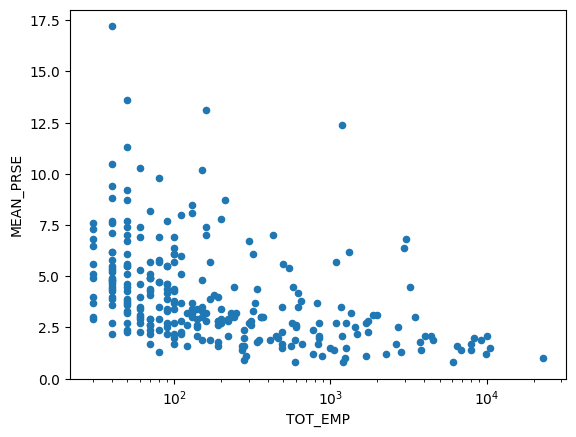

In [8]:
print(f"mean_prse = {(data["MEAN_PRSE"] > 20).sum()}, emp_prse = {(data["EMP_PRSE"] > 20).sum()}")
data.plot.scatter("TOT_EMP", "MEAN_PRSE", logx=True)

Wage error is predictably higher in smaller metros, shown here in metros with 120 or fewer data scientists employed. Still most error scores are under 10%, which is acceptable. 

In [9]:
for col in rent_cols:
    data[f"burden_med_{col.split('_')[1]}"] = (data[col] * 12) / data["A_MEDIAN"]
    data[f"burden_quart_{col.split('_')[1]}"] = (data[col] * 12) / data["A_PCT25"]

burden_med_cols = [col for col in data.columns if col.startswith("burden_med")]
data[burden_med_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
burden_med_mean,279.0,0.172163,0.043278,0.087145,0.141208,0.164735,0.192634,0.386074
burden_med_median,279.0,0.171361,0.043879,0.087892,0.139518,0.164291,0.192634,0.386074
burden_med_min,279.0,0.164547,0.046086,0.073692,0.131249,0.155617,0.189615,0.386074
burden_med_max,279.0,0.181071,0.043238,0.093303,0.152583,0.173928,0.200473,0.386074


In [10]:
burden_quart_cols = [col for col in data.columns if col.startswith("burden_quart")]
data[burden_quart_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
burden_quart_mean,279.0,0.223106,0.060572,0.108600,0.180739,0.213985,0.252556,0.549592
burden_quart_median,279.0,0.222109,0.061412,0.109531,0.179362,0.212595,0.252556,0.549592
burden_quart_min,279.0,0.213282,0.063974,0.091835,0.165236,0.204532,0.242923,0.549592
burden_quart_max,279.0,0.234552,0.060317,0.114290,0.195992,0.222345,0.260368,0.549592


This is a preliminary descriptive analysis of rent burden. In the average metro, the rent burden for a 2 bedroom apartment is well under the 30% income threshold., even in the more expensive subdivisions using a median wage or a first quartile (entry-level) wage.

<Axes: xlabel='log_rent', ylabel='log_wage'>

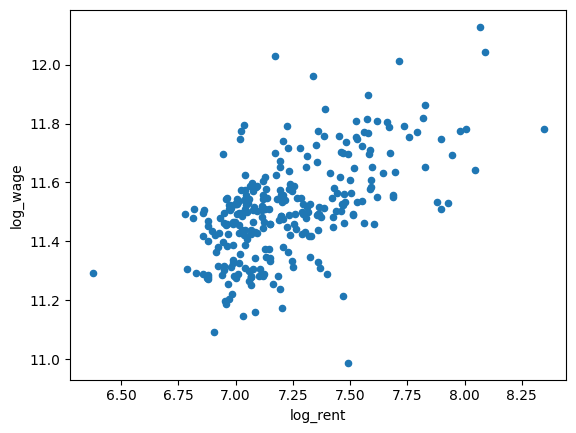

In [11]:
import numpy as np

data["log_wage"] = np.log(data["A_MEDIAN"])
data["log_rent"] = np.log(data["rent_median"])

data.plot.scatter("log_rent", "log_wage")

This plot shows a roughly linear relationship between rent and wage, which is as expected, wage increases with cost of living. The regression will show the slope of this relationship.

In [12]:
print("Largest burden areas")
display(data.nlargest(10, "burden_med_median")[["AREA_TITLE","A_MEDIAN","rent_median","burden_med_median"]])

Largest burden areas


,AREA_TITLE,A_MEDIAN,rent_median,burden_med_median
227,"Santa Cruz-Watsonville, CA",130980.0,4214.0,0.386074
267,"Waterbury-Shelton, CT",59160.0,1788.0,0.362677
228,"Santa Maria-Santa Barbara, CA",113990.0,3124.0,0.328871
170,"Napa, CA",101830.0,2773.0,0.326780
219,"Salinas, CA",99850.0,2684.0,0.322564
259,"Urban Honolulu, HI",102080.0,2642.0,0.310580
115,"Ithaca, NY",74170.0,1753.0,0.283619
229,"Santa Rosa-Petaluma, CA",119930.0,2827.0,0.282865
222,"San Diego-Chula Vista-Carlsbad, CA",130990.0,3001.0,0.274922
149,"Los Angeles-Long Beach-Anaheim, CA",129740.0,2918.5,0.269940


In [13]:
print("Smallest burden areas")
display(data.nsmallest(10, "burden_med_median")[["AREA_TITLE","A_MEDIAN","rent_median","burden_med_median"]])

Smallest burden areas


,AREA_TITLE,A_MEDIAN,rent_median,burden_med_median
225,"San Juan-Bayamon-Caguas, PR",80280.0,588.0,0.087892
112,"Idaho Falls, ID",167840.0,1304.5,0.093267
48,"Charlotte-Concord-Gastonia, NC-SC",132460.0,1138.0,0.103095
160,"Minneapolis-St. Paul-Bloomington, MN-WI",129780.0,1123.0,0.103837
190,"Peoria, IL",120000.0,1039.0,0.103900
233,"Sheboygan, WI",126270.0,1116.0,0.106058
133,"Lafayette, LA",98130.0,880.0,0.107612
217,"St. Louis, MO-IL",99600.0,916.0,0.110361
122,"Joplin, MO-KS",96650.0,912.0,0.113233
44,"Cedar Rapids, IA",99410.0,956.0,0.115401


In [14]:
print("Largest wage areas")
display(data.nlargest(10, "A_MEDIAN")[["AREA_TITLE","A_MEDIAN","rent_median","burden_med_median"]])

Largest wage areas


,AREA_TITLE,A_MEDIAN,rent_median,burden_med_median
224,"San Jose-Sunnyvale-Santa Clara, CA",185080.0,3192.5,0.206992
223,"San Francisco-Oakland-Fremont, CA",170110.0,3258.0,0.229828
112,"Idaho Falls, ID",167840.0,1304.5,0.093267
232,"Seattle-Tacoma-Bellevue, WA",164740.0,2236.0,0.162875
125,"Kennewick-Richland, WA",156830.0,1538.0,0.117682
177,"North Port-Bradenton-Sarasota, FL",146980.0,1958.0,0.159858
39,"Bridgeport-Stamford-Danbury, CT",141760.0,2511.0,0.212556
62,"Corvallis, OR",140190.0,1622.0,0.138840
175,"New York-Newark-Jersey City, NY-NJ",135980.0,2486.0,0.219385
254,"Trenton-Princeton, NJ",135320.0,1950.0,0.172923


In [22]:
print("Data Science hubs")
display(data.nlargest(10, "JOBS_1000")[["AREA_TITLE","A_MEDIAN","rent_median","burden_med_median", "JOBS_1000", "TOT_EMP"]])

Data Science hubs


,AREA_TITLE,A_MEDIAN,rent_median,burden_med_median,JOBS_1000,TOT_EMP
31,"Bloomington, IL",120760.0,1302.0,0.129381,6.744,590.0
224,"San Jose-Sunnyvale-Santa Clara, CA",185080.0,3192.5,0.206992,5.339,6060.0
223,"San Francisco-Oakland-Fremont, CA",170110.0,3258.0,0.229828,4.407,10460.0
232,"Seattle-Tacoma-Bellevue, WA",164740.0,2236.0,0.162875,4.011,8370.0
75,"Durham-Chapel Hill, NC",106500.0,1329.5,0.149803,3.841,1320.0
220,"Salt Lake City-Murray, UT",114990.0,1494.0,0.155909,3.596,2970.0
48,"Charlotte-Concord-Gastonia, NC-SC",132460.0,1138.0,0.103095,3.254,4420.0
185,"Oshkosh-Neenah, WI",100920.0,1149.0,0.136623,3.120,290.0
71,"Des Moines-West Des Moines, IA",103030.0,1163.0,0.135456,3.074,1240.0
266,"Washington-Arlington-Alexandria, DC-VA-MD-WV",132200.0,1375.0,0.124811,2.954,9260.0


In [15]:
d = data.dropna(subset=["log_rent", "log_wage"]).copy()
for label, cond in [("high rent", d.log_rent > 8.2), ("low rent", d.log_rent < 6.6),
                    ("high wage", d.log_wage > 11.95), ("low wage", d.log_wage < 11.1)]:
    print(label)
    display(d.loc[cond, ["AREA_TITLE", "A_MEDIAN", "rent_median", "TOT_EMP", "MEAN_PRSE"]])

high rent


,AREA_TITLE,A_MEDIAN,rent_median,TOT_EMP,MEAN_PRSE
227,"Santa Cruz-Watsonville, CA",130980.0,4214.0,80.0,3.5


low rent


,AREA_TITLE,A_MEDIAN,rent_median,TOT_EMP,MEAN_PRSE
225,"San Juan-Bayamon-Caguas, PR",80280.0,588.0,70.0,1.7


high wage


,AREA_TITLE,A_MEDIAN,rent_median,TOT_EMP,MEAN_PRSE
112,"Idaho Falls, ID",167840.0,1304.5,230.0,3.0
125,"Kennewick-Richland, WA",156830.0,1538.0,150.0,1.9
223,"San Francisco-Oakland-Fremont, CA",170110.0,3258.0,10460.0,1.5
224,"San Jose-Sunnyvale-Santa Clara, CA",185080.0,3192.5,6060.0,0.8
232,"Seattle-Tacoma-Bellevue, WA",164740.0,2236.0,8370.0,2.0


low wage


,AREA_TITLE,A_MEDIAN,rent_median,TOT_EMP,MEAN_PRSE
36,"Bowling Green, KY",65620.0,996.0,40.0,6.2
267,"Waterbury-Shelton, CT",59160.0,1788.0,170.0,5.7


These are the outliers for rent and wage in the scatterplot above. 

In [16]:
data.to_parquet(PROCESSED / "03_processed.parquet", index=False)